<a href="https://colab.research.google.com/github/KatiaItzelCortes/Simulaci-n-2/blob/main/Caminata_aleatoria_sobre_un_grafo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Caminata Aleatoria sobre un Grafo

Consideramos una secuencia de ceros $0$ y unos $1$ de longitud $m$. Llamamos **buena cadena** a aquella secuencia que no contiene unos adyacentes.

El objetivo es calcular el número esperado (valor esperado) de 1's si asumimos que todas las buenas cadenas son igualmente probables. Matemáticamente, el valor esperado $\mu$ está dado por:
$$\mu = \sum_k k \pi_k$$
donde $\pi_k$ es la probabilidad de que una buena secuencia tenga $k$ unos.

Para resolver esto, realizaremos una caminata aleatoria sobre el grafo donde:
* Nodos (Vértices): Son todas las "buenas cadenas" válidas.
* Aristas (Enlaces): Conectan dos cadenas que difieren exactamente en un bit.

In [31]:
import numpy as np
import matplotlib.pyplot as plt

In [32]:
def buena_cadena(cadena, i, valor2):
    if valor2 == 0:
        return True

    m = len(cadena)
    if i > 0 and cadena[i-1] == 1:
        return False # Falla por la izquierda
    if i < m - 1 and cadena[i+1] == 1:
        return False # Falla por la derecha
    return True

def cam_al_cad(m, num_pasos, n=1000):
    a = np.zeros(m, dtype=int)
    unos = []

    for paso in range(num_pasos + n):
        i = np.random.randint(0, m)

        nuevo_valor = 1 - a[i]

        if buena_cadena(a, i, nuevo_valor):
            a[i] = nuevo_valor # Aceptamos el movimiento

        if paso >= n:
            unos.append(np.sum(a))

    return np.array(unos)

Finalmente, resolvemos el problema general para una longitud de $m=100$.

In [33]:
m_f = 100
pasos_f = 100000
n_f = 5000

muestras_m100 = cam_al_cad(m_f, pasos_f, n=n_f)
solucion_f = np.mean(muestras_m100)

In [23]:
print(f"El número esperado de 1's para m={m_f}, son {solucion_f:.2f}")

El número esperado de 1's para m=100, son 27.87


Graficamos

/tmp/ipykernel_1732/2280667091.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


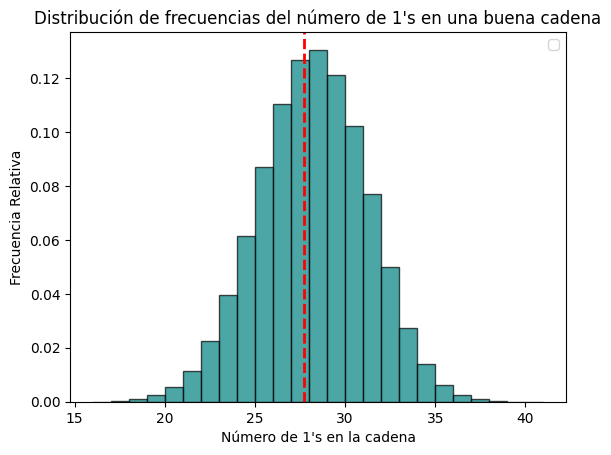

In [34]:
plt.hist(muestras_m100, bins=range(min(muestras_m100), max(muestras_m100) + 2),
         density=True, alpha=0.7, color='teal', edgecolor='black')

plt.title('Distribución de frecuencias del número de 1\'s en una buena cadena')
plt.xlabel('Número de 1\'s en la cadena')
plt.ylabel('Frecuencia Relativa')
plt.axvline(solucion_f, color='red', linestyle='dashed', linewidth=2)

plt.legend()
plt.show()